# 06 · Tau PET Imaging EDA
> *Tau is a protein that forms toxic aggregates in brain diseases. Tau PET is an emerging biomarker being evaluated in PD/Parkinsonism.*

## Background: What is Tau PET?

**Tau** is a protein that normally stabilises microtubules inside neurons. In several neurodegenerative diseases, tau becomes abnormally phosphorylated, detaches from microtubules, and forms **neurofibrillary tangles** that damage and kill neurons.

**Tau pathology in PD:** Unlike Alzheimer's disease where tau is a primary driver, in PD tau pathology is **secondary** — but it appears to accelerate disease progression and cognitive decline in a subset of patients.

**Two tracers used in PPMI:**

| Tracer | Full Name | Notes |
|--------|----------|-------|
| **PI-2620** | ¹⁸F-PI-2620 | Also called florzolotau; selective for tau tangles |
| **MK-6240** | ¹⁸F-MK-6240 | High affinity for tau, low off-target binding |

**Measurement — SUVR (Standardised Uptake Value Ratio):**
> SUVR = (tracer uptake in target region) / (tracer uptake in reference region)

Reference region: **cerebellum** (assumed tau-free in most PD patients).
An SUVR > 1.0 indicates elevated tau deposition relative to the reference.

**Braak Staging Regions:**
Tau spreads in a predictable pattern through the brain (Braak stages 1–6). PET regions aligned to these stages track where tau has spread.

> ⚠️ **Small sample size warning:** Only ~23 participants have tau PET data. This is a pilot substudy — statistical interpretation requires caution.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data Files

In [3]:
tau_meta = pd.read_csv(DATA_DIR / 'TAU_PET_Metadata_12Nov2026.csv')
tau_anal = pd.read_csv(DATA_DIR / 'TAU_PET_Analysis_12Nov2026.csv')
mk6240   = pd.read_csv(DATA_DIR / 'Tau_Substudy_MK-6240_PET_Imaging_12Nov2026.csv')
pi2620   = pd.read_csv(DATA_DIR / 'NX_PI-2620_Tau_Imaging_Substudy_Imaging_12Nov2026.csv')
for name, df in [('TAU PET Metadata', tau_meta), ('TAU PET Analysis', tau_anal),
                 ('MK-6240 Substudy', mk6240), ('PI-2620 Substudy (NX)', pi2620)]:
    print(f'{name:30s}: {len(df):>4} rows | {df["PATNO"].nunique()} participants | {df.shape[1]} cols')

TAU PET Metadata              :   23 rows | 23 participants | 16 cols
TAU PET Analysis              :   23 rows | 23 participants | 9 cols
MK-6240 Substudy              :   23 rows | 23 participants | 20 cols
PI-2620 Substudy (NX)         :   30 rows | 22 participants | 21 cols


## Column Reference

### TAU PET Analysis
| Column | Meaning |
|--------|---------|
| `PET_LIGAND` | Tracer name (PI-2620 or MK-6240) |
| `TAU_SUVR_CBM` | SUVR in cerebellum (reference region — should be ~1.0) |
| Braak region columns | SUVR in regions corresponding to Braak tau staging |

### SUVR Interpretation
| SUVR Range | Interpretation |
|-----------|---------------|
| ~1.0 | Background — tau level similar to reference |
| 1.1–1.3 | Mild elevation |
| > 1.3 | Moderate-to-high tau deposition |

### Key Column Patterns
Columns ending in `_SUVR` or starting with `TAU_SUVR_` or `BRAAK_` represent regional SUVR values.

## 1 · Small Sample Size Caveat

In [4]:
print("=" * 60)
print("IMPORTANT: Small Sample Size Notice")
print("=" * 60)
print(f"TAU PET Analysis participants: {tau_anal['PATNO'].nunique()}")
print(f"MK-6240 substudy participants: {mk6240['PATNO'].nunique()}")
print(f"PI-2620 substudy participants: {pi2620['PATNO'].nunique()}")
print()
print("Tau PET in PPMI is a PILOT substudy.")
print("N ~23 is insufficient for robust statistical inference.")
print("Use these results for exploration and hypothesis generation only.")

IMPORTANT: Small Sample Size Notice
TAU PET Analysis participants: 23
MK-6240 substudy participants: 23
PI-2620 substudy participants: 22

Tau PET in PPMI is a PILOT substudy.
N ~23 is insufficient for robust statistical inference.
Use these results for exploration and hypothesis generation only.


## 2 · Tracer Distribution

In [5]:
if 'PET_LIGAND' in tau_meta.columns:
    lig = tau_meta['PET_LIGAND'].value_counts()
    fig, ax = plt.subplots(figsize=(8, 4))
    lig.plot(kind='bar', ax=ax, color=sns.color_palette('colorblind', len(lig)))
    ax.set_title('Tau PET Tracers Used'); ax.set_ylabel('Scans')
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.show(); print(lig)

## 3 · SUVR Distributions by Region

All SUVR values should hover near 1.0 in regions without tau; values > 1.1 suggest tau accumulation.

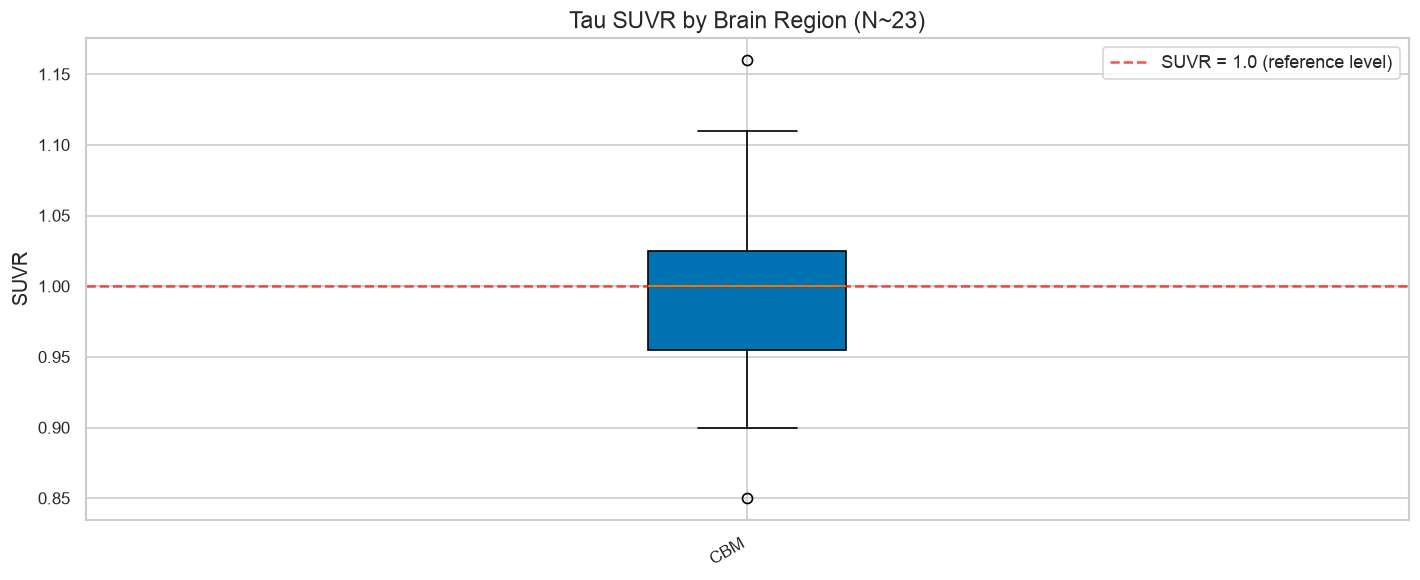

       TAU_SUVR_CBM
count        23.000
mean          0.998
std           0.070
min           0.850
25%           0.955
50%           1.000
75%           1.025
max           1.160


In [6]:
suvr_cols = [c for c in tau_anal.columns if 'SUVR' in c.upper() or 'BRAAK' in c.upper()]
suvr_cols = [c for c in suvr_cols if tau_anal[c].dtype in [np.float64, float]]

if suvr_cols:
    fig, ax = plt.subplots(figsize=(12, 5))
    data = [tau_anal[c].dropna().values for c in suvr_cols]
    bp = ax.boxplot(data, patch_artist=True)
    ax.set_xticks(range(1, len(suvr_cols)+1))
    ax.set_xticklabels([c.replace('TAU_SUVR_','').replace('_SUVR','') for c in suvr_cols], rotation=30, ha='right')
    colors = sns.color_palette('colorblind', len(suvr_cols))
    for patch, c in zip(bp['boxes'], colors): patch.set_facecolor(c)
    ax.axhline(1.0, color='red', linestyle='--', alpha=0.7, label='SUVR = 1.0 (reference level)')
    ax.set_title('Tau SUVR by Brain Region (N~23)')
    ax.set_ylabel('SUVR'); ax.legend()
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.show()
    print(tau_anal[suvr_cols].describe().round(3))

## 4 · Individual Participant Profiles

With N=23, we can plot every individual — something impossible with larger datasets.

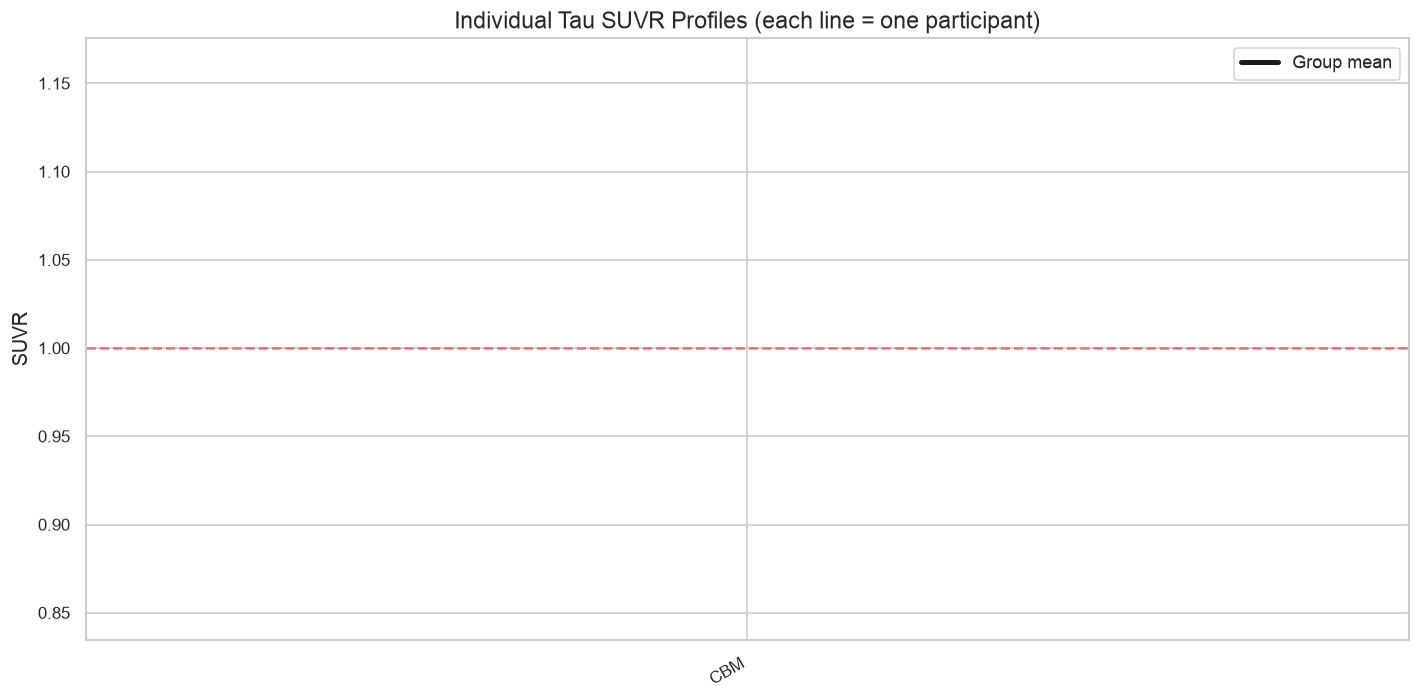

In [7]:
if suvr_cols:
    fig, ax = plt.subplots(figsize=(12, 6))
    x = range(len(suvr_cols))
    colors_p = sns.color_palette('tab20', n_colors=min(len(tau_anal), 20))
    for i, (_, row) in enumerate(tau_anal[suvr_cols].dropna().iterrows()):
        ax.plot(x, row.values, alpha=0.4, linewidth=1, color=colors_p[i % len(colors_p)])
    mean_vals = tau_anal[suvr_cols].mean()
    ax.plot(x, mean_vals.values, 'k-', linewidth=3, label='Group mean')
    ax.axhline(1.0, color='red', linestyle='--', alpha=0.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels([c.replace('TAU_SUVR_','').replace('_SUVR','') for c in suvr_cols],
                       rotation=30, ha='right')
    ax.set_ylabel('SUVR'); ax.set_title('Individual Tau SUVR Profiles (each line = one participant)')
    ax.legend(); plt.tight_layout(); plt.show()

## 5 · Acquisition Metadata Summary

In [8]:
print("TAU PET Acquisition Metadata Summary:")
print(f"Total scans: {len(tau_meta)}")
print(f"Participants: {tau_meta['PATNO'].nunique()}")
print()
num_cols = tau_meta.select_dtypes(include='number').columns.difference(['PATNO'])
if len(num_cols) > 0:
    print(tau_meta[num_cols].describe().round(2))
cat_cols = tau_meta.select_dtypes(include='object').columns.difference(['EVENT_ID','INFODT','ORIG_ENTRY','LAST_UPDATE'])
for col in cat_cols[:5]:
    vc = tau_meta[col].value_counts()
    if 1 < len(vc) <= 10:
        print(f"\n{col}:"); print(vc.to_string())

TAU PET Acquisition Metadata Summary:
Total scans: 23
Participants: 23

       PROTOCOL  TAU_INJECTION_VOLUME  TAU_SCAN_QUALITY_RATING  \
count      23.0                 23.00                    23.00   
mean        8.0                  1.07                     2.35   
std         0.0                  0.94                     0.57   
min         8.0                  0.30                     1.00   
25%         8.0                  0.56                     2.00   
50%         8.0                  0.79                     2.00   
75%         8.0                  1.06                     3.00   
max         8.0                  4.18                     3.00   

       TAU_TOTAL_DOSE_CALC  TAU_WEIGHT  
count                23.00       23.00  
mean                192.29       86.11  
std                   4.98       16.45  
min                 180.78       59.80  
25%                 188.16       77.20  
50%                 193.84       82.80  
75%                 196.36       94.60  
max  

## Key Takeaways

- **Very small pilot dataset (N~23)** — treat findings as hypothesis-generating only
- **Two tracers used:** PI-2620 and MK-6240 — both target tau tangles but differ in pharmacokinetics
- **SUVR values cluster near 1.0** — expected in a PD cohort (tau is secondary; primary in Alzheimer's)
- **Individual profiles** are visible at this small N — useful for case-by-case exploration
- **Tau PET is a growing area** — expect more data as the PPMI-3 protocol expands substudy enrolment